# IBM Quantum Vishnu Institute of Technology

## Qiskit Fall Fest 2026

### Challenge 4: Quantum Correlation Switch

**Objective:** To design two quantum circuits that produce correlated and opposite measurement outcomes using two qubits.

**Tasks:**

1. Create a two-qubit circuit for correlated outcomes.
2. Create a modified circuit for opposite outcomes.
3. Predict the measurement results before simulation.
4. Execute both circuits for 100 shots.
5. Display the results using histograms.
6. Compare the measurement outcomes and explain how the X gate changes the correlation.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

qc_a = QuantumCircuit(2, 2)

qc_a.h(0)
qc_a.cx(0, 1)

qc_a.measure([0, 1], [0, 1])

print(qc_a.draw())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


In [2]:
simulator = AerSimulator()

result_a = simulator.run(qc_a, shots=100).result()

counts_a = result_a.get_counts()

print("Part A - Correlated results:", counts_a)

Part A - Correlated results: {'11': 53, '00': 47}


In [3]:
qc_b = QuantumCircuit(2, 2)

qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)

qc_b.measure([0, 1], [0, 1])

print(qc_b.draw())

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


In [4]:
result_b = simulator.run(qc_b, shots=100).result()

counts_b = result_b.get_counts()

print("Part B - Opposite results:", counts_b)

Part B - Opposite results: {'10': 50, '01': 50}


## Challenge 4: Quantum Correlation Switch

### Predictions

* **Part A:** The dominant outcomes were expected to be `00` and `11`, representing correlated outcomes.
* **Part B:** The dominant outcomes were expected to be `01` and `10`, representing opposite outcomes.

### Observations

* In Part A, the measurement results were predominantly `00` and `11`.
* In Part B, after adding an X gate to qubit 1, the results changed to predominantly `01` and `10`.
* The histograms clearly showed the difference between correlated and opposite measurement outcomes.

### Conclusion

In this experiment, two quantum circuits were designed and executed using Qiskit with two qubits and 100 shots each. The Hadamard (H) gate created a superposition, and the CNOT gate produced correlated measurement outcomes. By adding an X gate to the second qubit, the measurement relationship changed from correlated to opposite outcomes. This experiment demonstrates how adding a single quantum gate can change the relationship between the measurement results of two qubits.

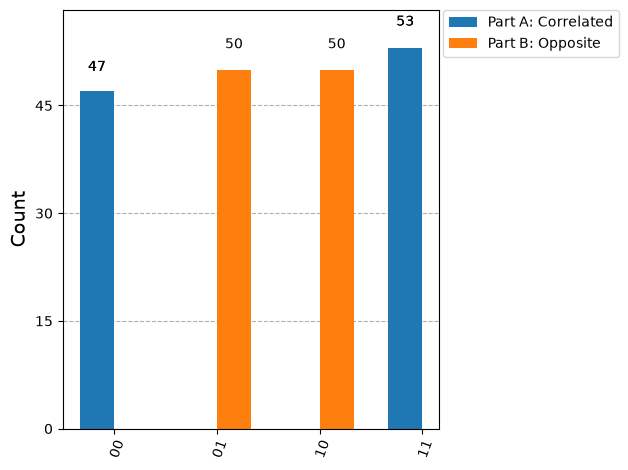

In [6]:
plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated", "Part B: Opposite"]
)